In [1]:
#@title Installings
!pip install huggingface_hub tqdm
!pip install webdataset zarr
!wget https://raw.githubusercontent.com/IBM/terramind/refs/heads/main/notebooks/plotting_utils.py
!pip install git+https://github.com/IBM/terratorch.git
!pip install rioxarray matplotli

--2026-04-11 12:00:57--  https://raw.githubusercontent.com/IBM/terramind/refs/heads/main/notebooks/plotting_utils.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8432 (8.2K) [text/plain]
Saving to: ‘plotting_utils.py.1’

plotting_utils.py.1 100%[===================>]   8.23K  --.-KB/s    in 0s      

2026-04-11 12:00:57 (58.0 MB/s) - ‘plotting_utils.py.1’ saved [8432/8432]

  Cloning https://github.com/IBM/terratorch.git to /tmp/pip-req-build-eyezb3i_
  Running command git clone --filter=blob:none --quiet https://github.com/IBM/terratorch.git /tmp/pip-req-build-eyezb3i_
  Resolved https://github.com/IBM/terratorch.git to commit 13b932e2560174eb6dcc93db939f9677fbd7f4dd
  Installing build dependencies ... done
  Getting requirements to build wheel ... done


In [2]:
#@title Imports
import os
import torch
import numpy as np
from terratorch.models.backbones.terramind.model.terramind_register import v1_pretraining_mean, v1_pretraining_std
import rioxarray as rxr
import matplotlib.pyplot as plt
from terratorch.registry import FULL_MODEL_REGISTRY
from plotting_utils import plot_s2, plot_modality
import io, tempfile
from zarr.storage import ZipStore
import xarray as xr
import torch.nn.functional as F
import webdataset as wds

# Select device
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [3]:
input_modalities = ['S2L2A']
output_modalities = ['S2L2A']

model = FULL_MODEL_REGISTRY.build(
    'terramind_v1_tiny_generate',
    modalities=input_modalities,  # Define the input
    output_modalities = output_modalities,  # Define the output from S2L2A, S1GRD, S1RTC, DEM, LULC, and NDVI
    pretrained=True,
    standardize=True,  # If standardize=True, you don't need to do the standardization yourself.
    # offset={'S2L2A': 1000}  # Optional offset in your data. The offset is also applied to the generation.
)

model = model.to(device)
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


TerraMind_Tokenizer_S2L2A.pt:   0%|          | 0.00/1.16G [00:00<?, ?B/s]

TerraMind_v1_tiny.pt:   0%|          | 0.00/212M [00:00<?, ?B/s]

TerraMindGeneration(
  (sampler): GenerationSampler(
    (model): TerraMind(
      (encoder_embeddings): ModuleDict(
        (untok_sen2l2a@224): ImageEncoderEmbedding(
          (proj): Linear(in_features=3072, out_features=192, bias=False)
        )
      )
      (decoder_embeddings): ModuleDict(
        (tok_sen2l2a@224): ImageTokenDecoderEmbedding(
          (token_emb): Embedding(15360, 192)
          (to_logits): Linear(in_features=192, out_features=15360, bias=False)
        )
      )
      (encoder): ModuleList(
        (0-11): 12 x Block(
          (norm1): LayerNorm()
          (attn): Attention(
            (qkv): Linear(in_features=192, out_features=576, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=192, out_features=192, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (drop_path): Identity()
          (norm2): LayerNorm()
          (mlp): Mlp(
            (fc1): Linear(in_fea

In [4]:
def extract_terramind_latent(model, input_batch, indices):
    # Assume model is already in .eval() and on the right device
    with torch.no_grad():
        # Optimized: Single pass for the whole batch
        emb_out = model.sampler.model.encoder_embeddings['untok_sen2l2a@224'](input_batch)
        x = emb_out['x'] if isinstance(emb_out, dict) else emb_out
        latents = []

        if 0 in indices:
            latents.append(model.sampler.model.encoder_norm(x).mean(dim=1).squeeze(0))

        for i, block in enumerate(model.sampler.model.encoder):
            x = block(x)
            if i+1 in indices:
                latents.append(model.sampler.model.encoder_norm(x).mean(dim=1).squeeze(0))


        return latents, indices # [indices, [Batch, 192]]

In [5]:
import math
from datetime import datetime

def get_day_angle(timestamp_str):
    """
    Converts a timestamp string to an angle in radians.
    0 -> January 1st
    pi -> Middle of the year
    2pi -> End of the year
    """
    # 1. Parse the date (ignoring nanoseconds beyond microseconds)
    dt = datetime.fromisoformat(timestamp_str.split('.')[0])

    # 2. Get the day of the year (1 to 365 or 366)
    day_of_year = dt.timetuple().tm_yday

    # 3. Determine the total days in that specific year (leap year check)
    year = dt.year
    is_leap = (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0)
    total_days = 366 if is_leap else 365

    # 4. Calculate the angle
    # We subtract 1 from day_of_year so that Jan 1st (Day 1) starts at exactly 0.0
    angle = ((day_of_year - 1) / total_days) * (2 * math.pi)

    return angle

def process_and_encode(sample, sample_dem, model, device, indices):
    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp:
        tmp.write(sample["zarr.zip"])
        tmp.flush()

        store = ZipStore(tmp.name, mode="r")
        ds = xr.open_zarr(store, consolidated=False)

    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp:
        tmp.write(sample_dem["zarr.zip"])
        tmp.flush()

        store = ZipStore(tmp.name, mode="r")
        ds_dem = xr.open_zarr(store, consolidated=False)
    # --- image ---
    img_dem = ds_dem["bands"].isel(time=0).values.astype("float32")
    img_dem = torch.tensor(img_dem)

    #--- elevation ---
    mean_elev = img_dem.mean()
    std_elev = img_dem.std()
    range_elev = img_dem.max() - img_dem.min()
    img = ds["bands"].isel(time=0).values.astype("float32") / 10000.0
    img = torch.tensor(img)

    # resize
    img = F.interpolate(img.unsqueeze(0), size=(224, 224), mode="bilinear")

    # --- time ---
    time = get_day_angle(str(ds["time"].isel(time=0).values))

    # --- cloud ---
    cloud = ds["cloud_mask"].isel(time=0).values
    cloud = torch.tensor(cloud).unsqueeze(0).float()
    cloud = F.interpolate(cloud.unsqueeze(0), size=(224, 224), mode="nearest")[0][0]
    cloud = cloud.mean()
    # --- lat/lon ---
    lat = float(ds["center_lat"].values)
    lon = float(ds["center_lon"].values)

    # --- encode ---
    img = img.to(device)
    latents, indices = extract_terramind_latent(model, img, indices)

    meta = [lat, lon, cloud, mean_elev, std_elev, range_elev, time]

    return latents, meta


In [6]:
from huggingface_hub import hf_hub_download

# --- 1. Authenticate (Only if the dataset is gated) ---
# You can run `huggingface-cli login` in your terminal or use:
# from huggingface_hub import login; login("your_token")
def generate_dataset(id):
  print()
  print('Loading:')
  REPO_ID = "ibm-esa-geospatial/TerraMesh"
  SHARD = f"majortom_shard_00000{id}.tar"
  print(SHARD)

  # --- 2. Download shards to local cache ---
  # This returns the local file path on your machine
  local_s2 = hf_hub_download(repo_id=REPO_ID, filename=f"train/S2L2A/{SHARD}", repo_type="dataset")
  local_dem = hf_hub_download(repo_id=REPO_ID, filename=f"train/DEM/{SHARD}", repo_type="dataset")

  # --- 3. Initialize WebDataset from local files ---
  ds_s2 = wds.WebDataset(local_s2, shardshuffle=False).decode()
  ds_dem = wds.WebDataset(local_dem, shardshuffle=False).decode()
  # Join streams
  return zip(ds_s2, ds_dem)

In [16]:
import time
import psutil
import os
import gc
import torch

def check_memory(threshold_gb=1.5): # Slightly higher threshold for safety
    """Returns True if available RAM is below threshold."""
    mem = psutil.virtual_memory()
    available_gb = mem.available / (1024**3)
    return available_gb < threshold_gb

# --- Setup ---
count = 0
count_to_check = 1000
max_count = 100000
indices = [0, 2, 4, 6, 8, 10, 12]
dataset_indices = range(1, 10)
start_time = time.time()

# We will collect everything in a global list for the FINAL save if RAM allows,
# but we save individual shards as backups.
all_meta = []
all_latents = [[] for _ in indices]

for ds_idx in dataset_indices:
    count_start = count
    print(f"\n🔄 Starting Shard {ds_idx}...")

    # 1. Generate the dataset stream
    dataset = generate_dataset(ds_idx)

    # Track data for THIS shard specifically to allow clearing
    shard_meta = []
    shard_latents = [[] for _ in indices]

    for sample, sample_dem in dataset:
        count += 1

        # 2. Process and Encode
        # Note: Ensure your process_and_encode calls ds.close() and store.close()
        current_latents, current_meta = process_and_encode(sample, sample_dem, model, device, indices)

        # 3. Append to Shard Lists
        shard_meta.append(current_meta)
        for i in range(len(shard_latents)):
            shard_latents[i].append(current_latents[i])

        # 4. Logging & Emergency Check
        if count % count_to_check == 0:
            if check_memory(threshold_gb=1.0):
                print(f"🚨 EMERGENCY STOP: RAM is low. Saving shard {ds_idx} and exiting loop.")
                break

            duration = time.time() - start_time
            avg_per_sample = duration / count_to_check
            print(f"✅ Total: {count} | Last 1000: {duration:.1f}s | Avg: {avg_per_sample:.3f}s/sample | RAM: {psutil.virtual_memory().percent}%")
            start_time = time.time()

        if count >= max_count:
            break

    # 5. Save Shard Progress to Disk (Safety Backup)
    print(f"💾 Shard {ds_idx} finished. Saving {len(shard_meta)} samples...")
    for i, idx in enumerate(indices):
        torch.save({
            "latents": torch.stack(shard_latents[i]),
            "meta": torch.tensor(shard_meta)
        }, f"/content/latents_layer{idx}_shard{ds_idx}.pt")

    # 6. Move shard data to global list and FORCE CLEAR RAM
    all_meta.extend(shard_meta)
    for i in range(len(indices)):
        all_latents[i].extend(shard_latents[i])

    # Explicitly delete shard-specific variables and collect garbage
    del shard_latents, shard_meta, dataset
    gc.collect()

    print(f"Loaded {count - count_start} samples from Shard {ds_idx}")

    if count >= max_count:
        break

# --- Final Save of Consolidated Data ---
print("\n🏁 Finalizing: Saving consolidated files...")
for i, idx in enumerate(indices):
    torch.save({
        "latents": torch.stack(all_latents[i]),
        "meta": torch.tensor(all_meta)
    }, f"/content/latents_{idx}_{count}.pt")

print("✨ All layers saved successfully.")


🔄 Starting Shard 1...

Loading:
majortom_shard_000001.tar
✅ Total: 1000 | Last 1000: 63.4s | Avg: 0.063s/sample | RAM: 35.6%
✅ Total: 2000 | Last 1000: 63.1s | Avg: 0.063s/sample | RAM: 35.6%
✅ Total: 3000 | Last 1000: 62.1s | Avg: 0.062s/sample | RAM: 35.6%
✅ Total: 4000 | Last 1000: 60.8s | Avg: 0.061s/sample | RAM: 35.6%
✅ Total: 5000 | Last 1000: 60.9s | Avg: 0.061s/sample | RAM: 35.6%
✅ Total: 6000 | Last 1000: 60.0s | Avg: 0.060s/sample | RAM: 35.7%
✅ Total: 7000 | Last 1000: 61.3s | Avg: 0.061s/sample | RAM: 35.7%
✅ Total: 8000 | Last 1000: 60.4s | Avg: 0.060s/sample | RAM: 35.8%
✅ Total: 9000 | Last 1000: 60.1s | Avg: 0.060s/sample | RAM: 35.7%
✅ Total: 10000 | Last 1000: 60.5s | Avg: 0.061s/sample | RAM: 35.7%
💾 Shard 1 finished. Saving 10240 samples...
Loaded 10240 samples from Shard 1

🔄 Starting Shard 2...

Loading:
majortom_shard_000002.tar


train/S2L2A/majortom_shard_000002.tar:   0%|          | 0.00/6.36G [00:00<?, ?B/s]

train/DEM/majortom_shard_000002.tar:   0%|          | 0.00/396M [00:00<?, ?B/s]

✅ Total: 11000 | Last 1000: 137.2s | Avg: 0.137s/sample | RAM: 36.1%
✅ Total: 12000 | Last 1000: 60.2s | Avg: 0.060s/sample | RAM: 36.0%
✅ Total: 13000 | Last 1000: 59.5s | Avg: 0.060s/sample | RAM: 36.1%
✅ Total: 14000 | Last 1000: 60.4s | Avg: 0.060s/sample | RAM: 36.2%
✅ Total: 15000 | Last 1000: 60.5s | Avg: 0.061s/sample | RAM: 36.1%
✅ Total: 16000 | Last 1000: 60.0s | Avg: 0.060s/sample | RAM: 36.1%
✅ Total: 17000 | Last 1000: 59.5s | Avg: 0.059s/sample | RAM: 36.1%
✅ Total: 18000 | Last 1000: 59.6s | Avg: 0.060s/sample | RAM: 36.3%
✅ Total: 19000 | Last 1000: 57.6s | Avg: 0.058s/sample | RAM: 36.1%
✅ Total: 20000 | Last 1000: 58.2s | Avg: 0.058s/sample | RAM: 36.1%
💾 Shard 2 finished. Saving 10240 samples...
Loaded 10240 samples from Shard 2

🔄 Starting Shard 3...

Loading:
majortom_shard_000003.tar


train/S2L2A/majortom_shard_000003.tar:   0%|          | 0.00/6.36G [00:00<?, ?B/s]

train/DEM/majortom_shard_000003.tar:   0%|          | 0.00/397M [00:00<?, ?B/s]

... (15 outputs left out)

✅ Total: 72000 | Last 1000: 160.4s | Avg: 0.160s/sample | RAM: 37.2%
✅ Total: 73000 | Last 1000: 58.1s | Avg: 0.058s/sample | RAM: 37.3%
✅ Total: 74000 | Last 1000: 57.9s | Avg: 0.058s/sample | RAM: 37.2%
✅ Total: 75000 | Last 1000: 60.3s | Avg: 0.060s/sample | RAM: 37.2%
✅ Total: 76000 | Last 1000: 59.4s | Avg: 0.059s/sample | RAM: 37.2%
✅ Total: 77000 | Last 1000: 59.4s | Avg: 0.059s/sample | RAM: 37.3%
✅ Total: 78000 | Last 1000: 59.9s | Avg: 0.060s/sample | RAM: 37.2%
✅ Total: 79000 | Last 1000: 58.3s | Avg: 0.058s/sample | RAM: 37.2%
✅ Total: 80000 | Last 1000: 58.2s | Avg: 0.058s/sample | RAM: 37.3%
✅ Total: 81000 | Last 1000: 59.3s | Avg: 0.059s/sample | RAM: 37.3%
💾 Shard 8 finished. Saving 10240 samples...
Loaded 10240 samples from Shard 8

🔄 Starting Shard 9...

Loading:
majortom_shard_000009.tar


train/S2L2A/majortom_shard_000009.tar:   0%|          | 0.00/6.36G [00:00<?, ?B/s]

train/DEM/majortom_shard_000009.tar:   0%|          | 0.00/396M [00:00<?, ?B/s]

✅ Total: 82000 | Last 1000: 157.5s | Avg: 0.157s/sample | RAM: 37.4%
✅ Total: 83000 | Last 1000: 58.9s | Avg: 0.059s/sample | RAM: 37.4%
✅ Total: 84000 | Last 1000: 58.9s | Avg: 0.059s/sample | RAM: 37.4%
✅ Total: 85000 | Last 1000: 59.9s | Avg: 0.060s/sample | RAM: 37.4%
✅ Total: 86000 | Last 1000: 60.9s | Avg: 0.061s/sample | RAM: 37.3%
✅ Total: 87000 | Last 1000: 59.9s | Avg: 0.060s/sample | RAM: 37.3%
✅ Total: 88000 | Last 1000: 59.2s | Avg: 0.059s/sample | RAM: 37.3%
✅ Total: 89000 | Last 1000: 59.5s | Avg: 0.059s/sample | RAM: 37.4%
✅ Total: 90000 | Last 1000: 58.1s | Avg: 0.058s/sample | RAM: 37.3%
✅ Total: 91000 | Last 1000: 58.6s | Avg: 0.059s/sample | RAM: 37.4%
✅ Total: 92000 | Last 1000: 59.8s | Avg: 0.060s/sample | RAM: 37.3%
💾 Shard 9 finished. Saving 10240 samples...
Loaded 10240 samples from Shard 9

🏁 Finalizing: Saving consolidated files...
✨ All layers saved successfully.


In [ ]:
# save once
for i, idx in enumerate(indices):
    torch.save({
        "latents": torch.stack(latents[i]),
        "meta": torch.tensor(meta)
    }, f"/content/latents_{idx}_{count-1}.pt")


Loading:
majortom_shard_000001.tar


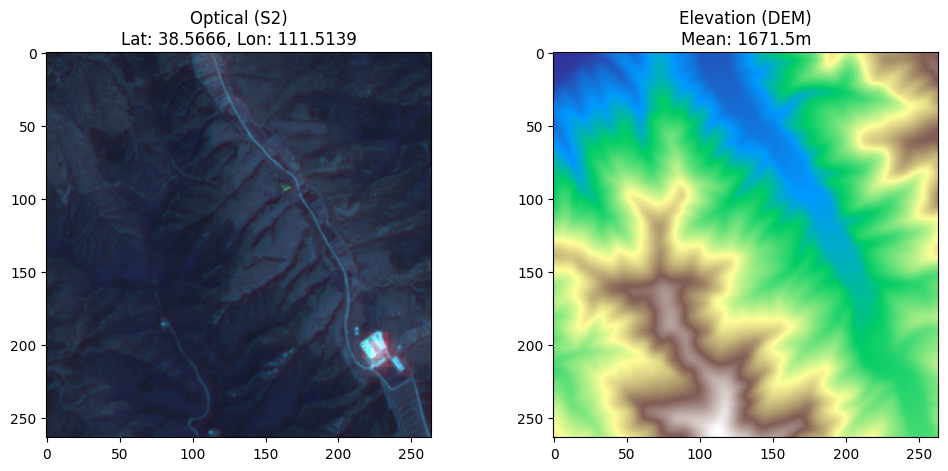

--- Sample Metadata ---
Cloud Score: 0.0000
Elevation Mean: 1671.47
Elevation Std: 89.77
Elevation Range: 449.00


In [14]:
def quick_check_fixed(dataset, model, device):
    # 1. Grab one pair from your zipped dataset
    sample, sample_dem = next(iter(dataset))

    # 2. Use YOUR working logic to get tensors
    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp:
        tmp.write(sample["zarr.zip"])
        tmp.flush()
        store = ZipStore(tmp.name, mode="r")
        ds = xr.open_zarr(store, consolidated=False)

        # Extract Optical & Cloud
        img = ds["bands"].isel(time=0).values.astype("float32") / 10000.0
        img_tensor = torch.tensor(img)
        cloud_mask = ds["cloud_mask"].isel(time=0).values
        lat = float(ds["center_lat"].values)
        lon = float(ds["center_lon"].values)

    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp_dem:
        tmp_dem.write(sample_dem["zarr.zip"])
        tmp_dem.flush()
        store_dem = ZipStore(tmp_dem.name, mode="r")
        ds_dem = xr.open_zarr(store_dem, consolidated=False)

        # Extract Elevation
        img_dem = ds_dem["bands"].isel(time=0).values.astype("float32").squeeze(0)
        img_dem_tensor = torch.tensor(img_dem)

    # 3. Simple Plotting
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Show Optical (RGB - usually first 3 bands)
    # Transpose from (C, H, W) to (H, W, C) for plt
    rgb_display = img_tensor[:3].permute(1, 2, 0).numpy()
    ax[0].imshow(np.clip(rgb_display * 3, 0, 1)) # Brighten slightly for view
    ax[0].set_title(f"Optical (S2)\nLat: {lat:.4f}, Lon: {lon:.4f}")

    # Show Elevation
    ax[1].imshow(img_dem_tensor.numpy(), cmap='terrain')
    ax[1].set_title(f"Elevation (DEM)\nMean: {img_dem_tensor.mean():.1f}m")

    plt.show()

    # 4. Print the "Labels" you need
    print(f"--- Sample Metadata ---")
    print(f"Cloud Score: {cloud_mask.mean():.4f}")
    print(f"Elevation Mean: {img_dem_tensor.mean():.2f}")
    print(f"Elevation Std: {img_dem_tensor.std():.2f}")
    print(f"Elevation Range: {img_dem_tensor.max() - img_dem_tensor.min():.2f}")

# Run it
dataset = generate_dataset(1)
quick_check_fixed(dataset, model, device)

In [12]:
import torch
import numpy as np

# 1. Load the file
path = "/content/latents_2_100.pt"
data = torch.load(path)

# 2. Extract components
saved_latents = data["latents"]
# Assuming meta was saved as a tensor of [lat, lon]
saved_meta = data["meta"]
# 3. Print Summary Stats
print("--- 📂 File Inspection: latents.pt ---")
print(f"Total Samples:    {saved_latents.shape[0]}")
print(f"Latent Shape:     {saved_latents.shape[1]}")

# 4. Detailed Metric Breakdown (First 5 Samples)
print("\n--- 🛰️ Extracted Metrics Per Sample ---")
header = f"{'Idx':<5} | {'Lat':<10} | {'Lon':<10} | {'Cloud':<8} | {'Mean Elev':<10} | {'Std Elev':<10} | {'Range Elev':<10} |{'Time angle':<10} | Latent Head"
print(header)
print("-" * len(header))

for i in range(min(5, len(saved_latents))):
    # If you saved extra metrics in 'meta' or a separate dict, adjust indexing here:
    lat, lon, cloud_score, mean_elev, std_elev, range_elev, time = saved_meta[i].tolist()

    # Example of how to pull the first few values of the latent for a "fingerprint"
    # Fix: Flatten the tensor before taking the first 3 elements to get a flat list of numbers
    fingerprint = saved_latents[i].flatten()[:3].tolist()
    fp_str = ", ".join([f"{x:.3f}" for x in fingerprint])

    print(f"{i:<5} | {lat:<10.4f} | {lon:<10.4f} | {cloud_score:<8.4f} | {mean_elev:<10.2f} | {std_elev:<10.2f} | {range_elev:<10.2f} | {time:<10.2f} | {fp_str}")

# 5. Numerical Health Check
print("\n--- 🔍 Numerical Health Check ---")
lat_std = saved_latents.std(dim=0).mean().item()
print(f"Average Latent Std Dev: {lat_std:.6f}")

if lat_std < 1e-6:
    print("⚠️  CRITICAL: Latent vectors are identical across samples. Check model input/normalization.")
elif torch.isnan(saved_latents).any():
    print("❌ ERROR: NaNs detected in the saved tensors.")
else:
    print("✅ Latents appear diverse and healthy.")

--- 📂 File Inspection: latents.pt ---
Total Samples:    100
Latent Shape:     192

--- 🛰️ Extracted Metrics Per Sample ---
Idx   | Lat        | Lon        | Cloud    | Mean Elev  | Std Elev   | Range Elev |Time angle | Latent Head
-----------------------------------------------------------------------------------------------------------
0     | 38.5666    | 111.5139   | 0.0000   | 1671.47    | 89.77      | 449.00     | 3.17       | 0.346, 0.214, 0.152
1     | 69.0627    | -91.5976   | 2.0000   | 183.71     | 8.12       | 48.00      | 2.90       | 0.441, 0.037, 0.316
2     | 11.4172    | 104.8779   | 0.1140   | 8.73       | 1.09       | 11.00      | 1.46       | 0.455, 0.225, 0.160
3     | 54.9352    | -72.0232   | 3.9155   | 439.94     | 18.00      | 75.00      | 5.89       | 0.676, 0.033, 0.284
4     | 26.2363    | 71.6623    | 0.0000   | 210.02     | 1.99       | 14.00      | 0.59       | 0.534, 0.257, 0.164

--- 🔍 Numerical Health Check ---
Average Latent Std Dev: 0.156730
✅ Latents